# 005 - Final results

The final method combines two stages. Stage 2 makes the **family / outlier** decision: `NearestFamilyThreshold` on provenance signals from the fine-tuned inverse decoders $D^{-1}$. Stage 4 makes the **size** decision: a logistic regression on generator-likelihood summaries. Stage 4 replaced Stage 2's size step for both families because both passed all of 004's pre-registered criteria. Stage 3 (token habits) passed none, so it left Stage 2 unchanged.

This notebook only reads cached outputs (`/workspace/cache/stage{1,2,3,4}/`) and runs on the CPU. It writes small summaries and figures to the repo's `results/`.

Sections: **0. Final method**; **1. All stages on val**; **2. Final model on val**; **3. Test predictions and submission**; **4. Test vs val**; **5. Final results**; **6. What carries the VAR size signal**.

## Setup

In [1]:
import sys, json
from pathlib import Path
REPO = Path("/workspace/iar-model-tracer")
sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tracer.common import CACHE
from tracer.metrics import report

RESULTS = REPO / "results"
RESULTS.mkdir(exist_ok=True)
STAGES = [1, 2, 3, 4]

## 0. Final method

```text
                                 image x  (256 x 256)
                                         |
              +--------------------------+--------------------------+
              |                                                     |
   RAR: D^-1_rar (fine-tuned, Stage 2)                 VAR: D^-1_var (fine-tuned, Stage 2)
   s_rar = quant  (latent quantisation error)          s_var = cal  (calibrated reconstruction loss)
              |                                                     |
              +--------------------------+--------------------------+
                                         |
               z_f = (log s_f - mu_f) / sd_f ,   f* = argmin_f z_f
                                         |
                      z_f* > tau_f*  (q = 0.95) ? ---- yes ---->  outlier
                                         | no
                                         v
                               family f* in {RAR, VAR}
                                         |
          tokens t = Q(D^-1_f*(x))   +   classes c_1..c_5 = top-5 of ConvNeXt-L (ImageNet)
                                         |
          for each of f*'s 4 transformers m and each class c_k:  log p~_m(t | c_k)  (teacher forcing)
                                         |
          class mixture per model  ->  per-model likelihood summaries (4 models x 5 or 6)
                                         |
                                         v
          size = argmax  LR_f*(summaries)       e.g. rarxl, var24        (Stage 4)
```

**1. Family or outlier (Stage 2, see 002).** Each family $f$ has a fine-tuned inverse decoder $D^{-1}_f$ (Zhao et al., Eq. 6) and one provenance loss $s_f$: the latent quantisation error for RAR (`rar_quant`, Eq. 5) and the calibrated reconstruction loss for VAR (`var_cal`, Eq. 10). Lower means more typical of $f$. With $\mu_f, \sigma_f$ the mean and standard deviation of $\log s_f$ over the family's train images,
$$z_f = \frac{\log s_f - \mu_f}{\sigma_f}, \qquad f^{\star} = \arg\min_f z_f, \qquad \text{outlier if } z_{f^{\star}} > \tau_{f^{\star}},$$
where $\tau_f$ is the $q = 0.95$ quantile of $z_f$ over the family's own train images. No outliers are used for fitting.

**2. Size (Stage 4, see 004).** For an image assigned to family $f^{\star}$:
- *Tokens.* The tokens are recovered as $t = Q(D^{-1}_{f^{\star}}(x))$ (Stage 3): 256 for RAR, 680 over 10 scales for VAR.
- *Classes.* The class is unknown, so the top-5 ImageNet classes $c_1 \dots c_5$ and their probabilities $\pi_k$ (renormalised over the top 5) come from torchvision `convnext_large`.
- *Likelihoods.* Each of the family's 4 transformers $m$ scores the tokens under its own guided sampling distribution $\tilde p_m$ (RAR: per-size guidance schedule and temperature; VAR: shared cfg schedule), for each class:
$$s_m(c_k) = \sum_{n=1}^{L} \log \tilde p_m(t_n \mid t_{<n}, c_k).$$
- *Class mixture.* With $a_{m,k} = \log \pi_k + s_m(c_k)$ and weights $w_{m,k} = \mathrm{softmax}_k(a_{m,k})$, each per-token summary is averaged over the classes with the weights $w_{m,k}$. The total becomes $\log \sum_k \pi_k\, \tilde p_m(t \mid c_k)$.
- *Classifier.* The size is the argmax of a standardised multinomial logistic regression on these per-model summaries: the mean of $\log p_{\text{cond}}$, $\log p_{\text{uncond}}$ and $\log \tilde p$, the mean rank, Min-20% and, for VAR, the top-$k$ / top-$p$ support rate. That gives 20 features for RAR and 24 for VAR. It is trained on generated images only (`stage3/gen` train split, 2,048 per model).

**Selection.** Every choice above was fixed in advance or selected on generated data or task train only. The Stage 2 settings come from `stage2/metrics.json`. The size step was replaced by 004's pre-registered swap rule: oracle, realistic and transfer criteria, then the classifier with the higher generated-holdout accuracy. Val is used only for evaluation, and test labels are never seen.

## 1. All stages on val

Val metrics of each stage's end-to-end rule (`tracer.metrics.report`, 450 images: 50 per known model and 50 outliers), read from `stage{1,2,3,4}/metrics.json`. For Stages 3 and 4 they are also recomputed from the saved val predictions (`val_predictions.csv`). Each value is checked against the val metrics table printed in that stage's notebook, to the precision printed there.

Size accuracy given family is measured over the known-family images whose family was predicted correctly. `family_recall_outlier` equals outlier recall and is kept for completeness.

In [2]:
COLS = ["accuracy", "family_accuracy", "outlier_recall", "outlier_precision", "size_accuracy_given_family",
        "family_recall_rar", "family_recall_var", "family_recall_outlier"]
METHOD = {1: "original encoders E (signals) + LR on signals (size)",
          2: "fine-tuned D^-1 (signals) + LR on signals (size)",
          3: "Stage 2; token-habit size step (no family passed, so unchanged)",
          4: "Stage 2 family / outlier + generator-likelihood LR (size)"}

# Val metrics as printed in each stage's notebook: (notebook, cell, decimals shown, values in COLS order).
REPORTED = {
    1: ("001_stage_1", 13, 3, [0.236, 0.838, 0.320, 0.533, 0.249, 0.925, 0.880, 0.320]),
    2: ("002_stage_2", 21, 3, [0.316, 0.960, 0.880, 0.863, 0.253, 0.960, 0.980, 0.880]),
    3: ("003_stage_3", 46, 6, [0.315556, 0.960000, 0.880000, 0.862745, 0.252577, 0.960000, 0.980000, 0.880000]),
    4: ("004_stage_4", 52, 4, [0.9400, 0.9600, 0.8800, 0.8627, 0.9768, 0.9600, 0.9800, 0.8800]),
}

rows = []
for st in STAGES:
    m = json.loads((CACHE / f"stage{st}" / "metrics.json").read_text())
    val = m["val"]
    assert val["n"] == 450
    if st in (3, 4):
        # The saved val predictions reproduce the saved metrics.
        p = pd.read_csv(CACHE / f"stage{st}" / "val_predictions.csv")
        rec = report(p.label, p.pred)
        assert all(np.isclose(rec[k], val[k]) for k in COLS), f"stage {st}: predictions do not match metrics.json"
    nb, cell, dec, ref = REPORTED[st]
    for k, r in zip(COLS, ref):
        assert abs(val[k] - r) <= 0.5 * 10 ** -dec + 1e-12, f"stage {st} {k}: {val[k]} vs {r} in {nb} cell {cell}"
    rows.append({"stage": st, "method": METHOD[st], **{k: val[k] for k in COLS}})
stages = pd.DataFrame(rows).set_index("stage")

# Stage 3 changed no label, and Stage 4 kept every family / outlier decision of Stage 2.
p3, p4 = (pd.read_csv(CACHE / f"stage{st}" / "val_predictions.csv") for st in (3, 4))
fam_of = lambda s: s.where(s == "outlier", s.str[:3])
assert (p3.key == p4.key).all() and (fam_of(p3.pred) == fam_of(p4.pred)).all()
swap = {st: json.loads((CACHE / f"stage{st}" / "metrics.json").read_text())["swap"] for st in (3, 4)}
assert swap[3] == {} and set(swap[4]) == {"rar", "var"}
print("all values match the stage notebooks; Stage 4 swap:", swap[4])

stages.to_csv(RESULTS / "stages_val.csv", float_format="%.6f")
display(stages.style.format("{:.3f}", subset=COLS))
print("wrote", RESULTS / "stages_val.csv")

all values match the stage notebooks; Stage 4 swap: {'rar': {'classifier': '(b) logistic regression', 'combination': 'B2 (ii) mix'}, 'var': {'classifier': '(b) logistic regression', 'combination': 'B2 (ii) mix'}}


,method,accuracy,family_accuracy,outlier_recall,outlier_precision,size_accuracy_given_family,family_recall_rar,family_recall_var,family_recall_outlier
stage,,,,,,,,,
1,original encoders E (signals) + LR on signals (size),0.236,0.838,0.320,0.533,0.249,0.925,0.880,0.320
2,fine-tuned D^-1 (signals) + LR on signals (size),0.316,0.960,0.880,0.863,0.253,0.960,0.980,0.880
3,"Stage 2; token-habit size step (no family passed, so unchanged)",0.316,0.960,0.880,0.863,0.253,0.960,0.980,0.880
4,Stage 2 family / outlier + generator-likelihood LR (size),0.940,0.960,0.880,0.863,0.977,0.960,0.980,0.880


wrote /workspace/iar-model-tracer/results/stages_val.csv


### Accuracy per stage

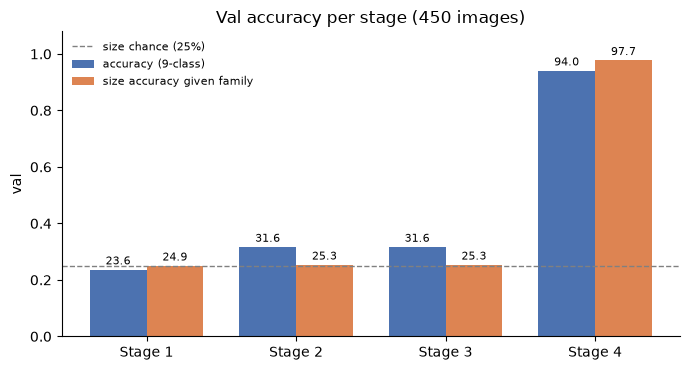

wrote /workspace/iar-model-tracer/results/stages_val.png


In [3]:
fig, ax = plt.subplots(figsize=(7, 3.8))
x, w = np.arange(len(STAGES)), 0.38
for i, (col, name, colour) in enumerate([("accuracy", "accuracy (9-class)", "#4c72b0"),
                                         ("size_accuracy_given_family", "size accuracy given family", "#dd8452")]):
    bars = ax.bar(x + (i - 0.5) * w, stages[col], w, label=name, color=colour)
    ax.bar_label(bars, labels=[f"{100 * v:.1f}" for v in stages[col]], fontsize=8, padding=2)
ax.axhline(0.25, color="grey", ls="--", lw=1, label="size chance (25%)")
ax.set_xticks(x, [f"Stage {s}" for s in STAGES])
ax.set_ylim(0, 1.08)
ax.set_ylabel("val")
ax.set_title("Val accuracy per stage (450 images)")
ax.legend(loc="upper left", fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(RESULTS / "stages_val.png", dpi=150)
plt.show()
print("wrote", RESULTS / "stages_val.png")

## 2. Final model on val

**Refit.** The final model is refit from the caches exactly as in 004:
- the Stage 2 rule from `stage2/features` and `stage2/metrics.json`;
- per family, the logistic regression on the B2 mixture (ii) summaries of the generated train split (`stage4/scores/<family>/gen_recovered_topk`, `stage3/gen_split.csv`);
- the size of every val image the rule assigns to RAR or VAR, from its `task_recovered_topk` scores.

The predictions must equal 004's saved val predictions label for label, and their metrics must equal 004's.

**Error types.** Each val error falls in exactly one of four types:
- *family error*: a RAR image called VAR, or the reverse;
- *outlier false positive*: a RAR or VAR image called outlier;
- *outlier miss*: an outlier given a family;
- *size error*: the correct family, the wrong size.

**Intervals.** 95% percentile bootstrap intervals use 2,000 resamples of the 450 val images (seed 0). Size accuracy given family is recomputed in each resample over that resample's known-family images with the correct family.

In [4]:
from scipy.special import logsumexp, softmax
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from PIL import Image

from tracer.common import DATA, LABELS, build_index
from tracer.generate import MODELS
from tracer.metrics import confusion, family_confusion
from tracer.stage1 import KNOWN_FAMILIES, NearestFamilyThreshold
from tracer.tokens import SEQ_LEN

S2, S3, S4 = CACHE / "stage2", CACHE / "stage3", CACHE / "stage4"
FINAL = CACHE / "final"
FINAL.mkdir(exist_ok=True)
SEED, N_BOOT = 0, 2000
SUMMARIES = {"rar": ["sum_logp_cond", "mean_logp_cond", "sum_logp_uncond", "mean_logp_uncond", "sum_logp_guided",
                     "mean_logp_guided", "sum_rank_guided", "mean_rank_guided", "min20_logp_guided",
                     "mean_cond_minus_uncond"]}
SUMMARIES["var"] = SUMMARIES["rar"] + ["sum_in_support", "mean_in_support", "in_support_rate"]


def lr_features(fam):
    # As in 004: five summaries per scoring model, plus the top-k / top-p support rate for VAR.
    per_model = ["mean_logp_cond", "mean_logp_uncond", "mean_logp_guided", "mean_rank_guided", "min20_logp_guided"]
    per_model += ["in_support_rate"] if fam == "var" else []
    return [f"{m}:{k}" for m in MODELS[fam] for k in per_model]


def mix(raw_run, fam):
    # 004's class mixture (ii): per model, weights w_k = softmax_k(log pi_k + s_m(c_k)) over the top-5 classes.
    out = {}
    for m, d in raw_run.items():
        log_pi = np.log(d["class_prob"] / d["class_prob"].sum(1, keepdims=True))
        a = log_pi + d["sum_logp_guided"].astype(np.float64)
        w = softmax(a, axis=1)
        vals = {k: (w * d[k]).sum(1) for k in SUMMARIES[fam]}
        vals["sum_logp_guided"] = logsumexp(a, axis=1)
        vals["mean_logp_guided"] = vals["sum_logp_guided"] / SEQ_LEN[fam]
        out.update({f"{m}:{k}": v for k, v in vals.items()})
    return pd.DataFrame(out)


def load_topk(fam, source, splits=None, root=S4 / "scores"):
    # Per-model top-5 summaries of a recovered-token run, with provenance checks; returns (ids, raw).
    raw, ids = {}, None
    for m in MODELS[fam]:
        run = root / fam / f"{source}_recovered_topk"
        cfg = json.loads((run / m / "config.json").read_text())
        assert (cfg["family"], cfg["source"], cfg["tokens"], cfg["class_mode"], cfg["topk"], cfg["model"], cfg["limit"],
                cfg["classes"]) == (fam, source, "recovered", "topk", 5, m, None, None), cfg
        if splits:
            assert sorted(cfg["splits"]) == sorted(splits), cfg
        z = np.load(run / f"{m}.npz")
        cur = pd.DataFrame({k: z[k] for k in (("row", "key") if source == "task" else ("row", "label", "index"))})
        ids = cur if ids is None else ids
        assert cur.equals(ids)
        raw[m] = {**{k: z[k].astype(np.float32) for k in SUMMARIES[fam]}, "class_prob": z["class_prob"]}
    return ids, raw


# 1. Stage 2 rule (family / outlier), refit as in 002 / 004.
m2 = json.loads((S2 / "metrics.json").read_text())
feat = {fam: pd.read_csv(S2 / "features" / f"{fam}.csv") for fam in KNOWN_FAMILIES}
df2 = feat["rar"].merge(feat["var"].drop(columns=["split", "label", "family", "name"]), on="key", validate="1:1")
idx = build_index()
assert df2.key.tolist() == idx.key.tolist()
train2, val2, test2 = (df2[df2.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
rule2 = NearestFamilyThreshold(m2["score_cols"], q=m2["q"], size_cols=m2["size_features"]).fit(train2)
pred2_val = rule2.predict(val2)
assert all(np.isclose(report(val2.label, pred2_val)[k], m2["val"][k]) for k in m2["val"])

# 2. Stage 4 size classifiers: LR on the B2 mixture summaries of the generated train split (the swap 004 selected).
m4 = json.loads((S4 / "metrics.json").read_text())
assert m4["swap"] == {fam: {"classifier": "(b) logistic regression", "combination": "B2 (ii) mix"}
                      for fam in KNOWN_FAMILIES}, m4["swap"]
split = pd.read_csv(S3 / "gen_split.csv")
SIZE_LR, GEN = {}, {}  # GEN: generated B2 mixture tables (Section 4 diagnostics)
for fam in KNOWN_FAMILIES:
    ids, raw = load_topk(fam, "gen")
    with np.load(S3 / "tokens" / fam / "gen.npz") as z:
        assert (ids.row.values == np.arange(len(z["label"]))).all()
        assert (ids.label.values == z["label"]).all() and (ids["index"].values == z["index"]).all()
    sp = split[split.family == fam].set_index(["label", "index"]).split
    t = pd.concat([ids, mix(raw, fam)], axis=1)
    t["split"] = sp.loc[list(zip(t.label, t["index"]))].values
    GEN[fam] = t
    tr = t[t.split == "train"]
    assert (tr.label.value_counts() == 2048).all()
    feats = lr_features(fam)
    SIZE_LR[fam] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(tr[feats], tr.label)
    print(f"{fam}: LR on {len(feats)} features, {len(tr)} generated train images")

# 3. Task images (all families and outliers), B2 mixture summaries indexed by key. Train + val are in
#    stage4/scores; test was scored separately into stage4/scores_test (004, Section 5).
def task_mix(splits, root):
    out = {}
    for fam in KNOWN_FAMILIES:
        ids, raw = load_topk(fam, "task", splits=splits, root=root)
        with np.load(S3 / "tokens" / fam / "task.npz") as z:
            assert (z["key"][ids.row.values] == ids.key.values).all()
        out[fam] = mix(raw, fam).set_index(pd.Index(ids.key.values, name="key"))
    return out


TASK = task_mix(["train", "val"], S4 / "scores")


def predict_final(d, task=TASK):
    # Stage 2 family / outlier; for RAR / VAR images the size is the Stage 4 LR's argmax over the family's models.
    pred = rule2.predict(d).values.copy()
    fam_pred = rule2.predict_family(d).values
    for fam in KNOWN_FAMILIES:
        m = fam_pred == fam
        if m.any():
            X = task[fam].loc[d.key.values[m], lr_features(fam)]
            lp = pd.DataFrame(SIZE_LR[fam].predict_log_proba(X), columns=SIZE_LR[fam].classes_)[MODELS[fam]]
            pred[m] = np.array(MODELS[fam])[lp.values.argmax(1)]
    return pd.Series(pred, index=d.index)


pred_val = predict_final(val2)
final_val = report(val2.label, pred_val)
ref = pd.read_csv(S4 / "val_predictions.csv")
assert (ref.key.values == val2.key.values).all() and (ref.pred.values == pred_val.values).all(), "differs from 004"
assert all(np.isclose(final_val[k], m4["val"][k]) for k in m4["val"]), "metrics differ from 004"
print(f"refit reproduces 004's val predictions (450 / 450 labels) and metrics: accuracy {final_val['accuracy']:.4f}, "
      f"size given family {final_val['size_accuracy_given_family']:.4f}")

rar: LR on 20 features, 8192 generated train images


var: LR on 24 features, 8192 generated train images
refit reproduces 004's val predictions (450 / 450 labels) and metrics: accuracy 0.9400, size given family 0.9768


### Confusion matrix and per-label metrics

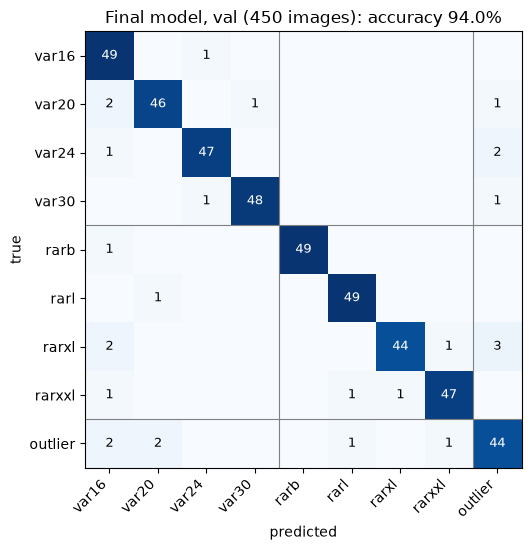

wrote /workspace/iar-model-tracer/results/confusion_val.png


,precision,recall,F1,support,predicted
label,,,,,
var16,0.845,0.980,0.907,50,58
var20,0.939,0.920,0.929,50,49
var24,0.959,0.940,0.949,50,49
var30,0.980,0.960,0.970,50,49
rarb,1.000,0.980,0.990,50,49
rarl,0.961,0.980,0.970,50,51
rarxl,0.978,0.880,0.926,50,45
rarxxl,0.959,0.940,0.949,50,49
outlier,0.863,0.880,0.871,50,51


pred,rar,var,outlier
true,,,
rar,192,5,3
var,0,196,4
outlier,2,4,44


In [5]:
cm = confusion(val2.label, pred_val)
fig, ax = plt.subplots(figsize=(6.4, 5.6))
ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=50)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        v = cm.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=9, color="white" if v > 25 else "black")
for b in (3.5, 7.5):  # VAR | RAR | outlier blocks
    ax.axhline(b, color="grey", lw=0.8)
    ax.axvline(b, color="grey", lw=0.8)
ax.set_xticks(range(len(LABELS)), cm.columns, rotation=45, ha="right")
ax.set_yticks(range(len(LABELS)), cm.index)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"Final model, val (450 images): accuracy {100 * final_val['accuracy']:.1f}%")
fig.tight_layout()
fig.savefig(RESULTS / "confusion_val.png", dpi=150)
plt.show()
print("wrote", RESULTS / "confusion_val.png")

p, r, f, n = precision_recall_fscore_support(val2.label, pred_val, labels=LABELS, zero_division=0)
per_label = pd.DataFrame({"precision": p, "recall": r, "F1": f, "support": n,
                          "predicted": [int((pred_val == l).sum()) for l in LABELS]}, index=pd.Index(LABELS, name="label"))
display(per_label.style.format("{:.3f}", subset=["precision", "recall", "F1"]))
display(family_confusion(val2.label, pred_val))

### Error breakdown

In [6]:
fam_of = lambda s: pd.Series(s).where(pd.Series(s) == "outlier", pd.Series(s).str[:3]).values
true_fam, pred_fam = fam_of(val2.label.values), fam_of(pred_val.values)
TYPES = ["family error (RAR <-> VAR)", "outlier false positive", "outlier miss", "size error (correct family)"]
err_type = np.select(
    [(true_fam != "outlier") & (pred_fam != "outlier") & (true_fam != pred_fam),
     (true_fam != "outlier") & (pred_fam == "outlier"),
     (true_fam == "outlier") & (pred_fam != "outlier"),
     (true_fam == pred_fam) & (true_fam != "outlier") & (val2.label.values != pred_val.values)],
    TYPES, default="")
wrong = val2.label.values != pred_val.values
assert ((err_type != "") == wrong).all()  # every error has exactly one type

counts = pd.Series(err_type[wrong]).value_counts().reindex(TYPES, fill_value=0)
breakdown = pd.DataFrame({"errors": counts, "share of errors": counts / wrong.sum(),
                          "decided by": ["Stage 2 (family / outlier)"] * 3 + ["Stage 4 (size)"]})
breakdown.loc["total"] = [int(wrong.sum()), 1.0, ""]
display(breakdown.style.format({"share of errors": "{:.1%}"}))
n_fam, n_size = int(counts[TYPES[:3]].sum()), int(counts[TYPES[3]])
assert wrong.sum() == 27 and n_fam == 18 and n_size == 9  # as reported in 004
print(f"{wrong.sum()} errors: {n_fam} family / outlier (inherited from Stage 2), {n_size} size")

pairs = (pd.DataFrame({"type": err_type, "true": val2.label, "predicted": pred_val})[wrong]
         .value_counts().rename("n").reset_index().sort_values(["type", "n"], ascending=[True, False]))
display(pairs.set_index(["type", "true", "predicted"]))

,errors,share of errors,decided by
family error (RAR <-> VAR),5,18.5%,Stage 2 (family / outlier)
outlier false positive,7,25.9%,Stage 2 (family / outlier)
outlier miss,6,22.2%,Stage 2 (family / outlier)
size error (correct family),9,33.3%,Stage 4 (size)
total,27,100.0%,


27 errors: 18 family / outlier (inherited from Stage 2), 9 size


n
type                        true    predicted   
family error (RAR <-> VAR)  rarxl   var16      2
                            rarb    var16      1
                            rarl    var20      1
                            rarxxl  var16      1
outlier false positive      rarxl   outlier    3
                            var24   outlier    2
                            var20   outlier    1
                            var30   outlier    1
outlier miss                outlier var20      2
                                    var16      2
                                    rarl       1
                                    rarxxl     1
size error (correct family) var20   var16      2
                            rarxl   rarxxl     1
                            rarxxl  rarxl      1
                                    rarl       1
                            var16   var24      1
                            var20   var30      1
                            var24   var16      1
                            var30   var24      1

### Misclassified val images

Ordered by error type, then true label. Titles show true → predicted.

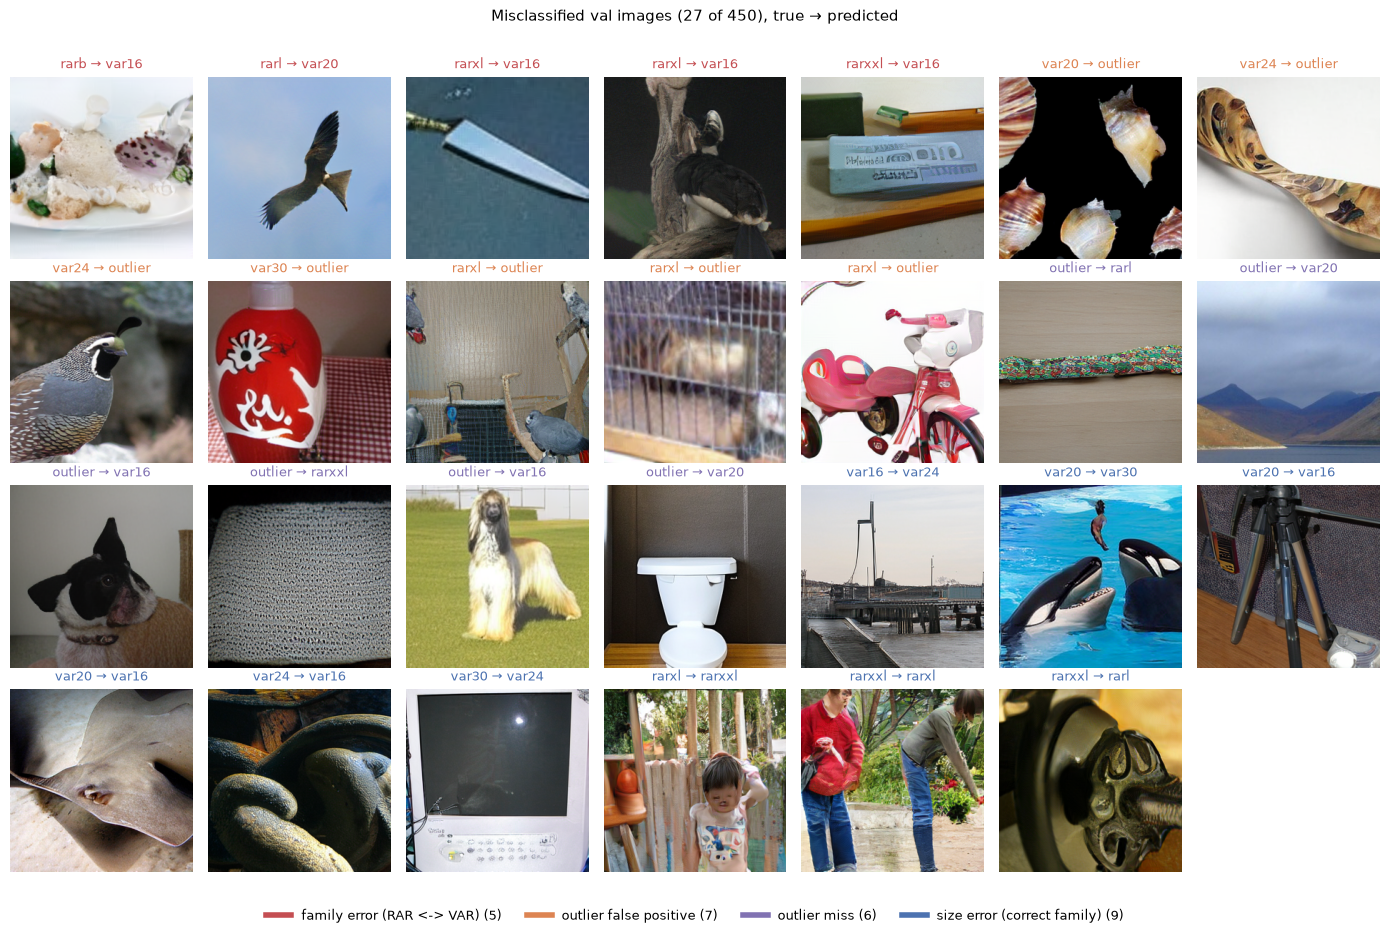

wrote /workspace/iar-model-tracer/results/errors_val.png


In [7]:
COLOURS = dict(zip(TYPES, ["#c44e52", "#dd8452", "#8172b2", "#4c72b0"]))
errs = (pd.DataFrame({"path": idx.set_index("key").loc[val2.key, "path"].values, "true": val2.label.values,
                      "pred": pred_val.values, "type": err_type})[wrong]
        .assign(t=lambda d: d.type.map(TYPES.index), l=lambda d: d.true.map(LABELS.index))
        .sort_values(["t", "l"]))
ncol = 7
nrow = int(np.ceil(len(errs) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(2.0 * ncol, 2.25 * nrow + 0.4))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, e) in zip(axes.flat, errs.iterrows()):
    ax.imshow(Image.open(e.path).convert("RGB"))
    ax.set_title(f"{e.true} → {e.pred}", fontsize=9, color=COLOURS[e.type])
fig.legend(handles=[plt.Line2D([], [], color=c, lw=4, label=f"{t} ({(errs.type == t).sum()})")
                    for t, c in COLOURS.items()], loc="lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle(f"Misclassified val images ({len(errs)} of {len(val2)}), true → predicted", fontsize=11)
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
fig.savefig(RESULTS / "errors_val.png", dpi=100)
plt.show()
print("wrote", RESULTS / "errors_val.png")

### Bootstrap intervals

In [8]:
def size_acc_given_family(y, p):
    tf, pf = fam_of(y), fam_of(p)
    m = (tf != "outlier") & (tf == pf)
    return (y[m] == p[m]).mean()


y, p = val2.label.values, pred_val.values
rng = np.random.default_rng(SEED)
boot = np.array([[np.mean(y[b] == p[b]), size_acc_given_family(y[b], p[b])]
                 for b in (rng.integers(0, len(y), len(y)) for _ in range(N_BOOT))])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
ci = pd.DataFrame({"val": [final_val["accuracy"], final_val["size_accuracy_given_family"]], "95% CI low": lo,
                   "95% CI high": hi,
                   "images": [len(y), int(((true_fam != "outlier") & (true_fam == pred_fam)).sum())]},
                  index=["accuracy", "size accuracy given family"])
assert np.isclose(ci.loc["size accuracy given family", "val"], size_acc_given_family(y, p))
display(ci.style.format("{:.3f}", subset=["val", "95% CI low", "95% CI high"]))

,val,95% CI low,95% CI high,images
accuracy,0.940,0.918,0.960,450
size accuracy given family,0.977,0.961,0.990,388


In [9]:
# Save the final val predictions.
out = pd.DataFrame({"key": val2.key, "image_name": val2.name, "label": val2.label, "pred": pred_val.values,
                    "family": true_fam, "pred_family": pred_fam, "error_type": err_type})
out.to_csv(FINAL / "pred_val.csv", index=False)
assert (pd.read_csv(FINAL / "pred_val.csv").pred.values == ref.pred.values).all()
print("wrote", FINAL / "pred_val.csv", f"({len(out)} rows)")

wrote /workspace/cache/final/pred_val.csv (450 rows)


## 3. Test predictions and submission

**Test predictions.** The test images go through the same code path as the val images (`predict_final`, the same steps as 004's `predict_stage4`): the Stage 2 rule, then the Stage 4 size step on the test scores in `stage4/scores_test`. The predictions must equal `stage4/submission_stage4.csv` row for row.

**Format, from `/workspace/data/task_template.py`.** The template only writes the CSV; it has no loader or checker.
- `LABELS = ["var16", "var20", "var24", "var30", "rarb", "rarl", "rarxl", "rarxxl", "outlier"]`, marked "Donot change this". These are the same strings as `tracer.common.LABELS`.
- Test images are listed by `TestDataset`: `sorted(Path(test).glob("*.*"))`, with `image_name = img_path.name`. That is the bare file name (e.g. `1234.png`), in lexicographic path order (`1.png, 10.png, 100.png, …`), with no directory.
- One row per test image, in that order (`DataLoader(shuffle=False)`), one label each.
- The file is written with `csv.writer` on a file opened with `newline=""` and `encoding="utf-8"`. The header row is `["image_name", "label"]`. The default `excel` dialect gives comma separators, minimal quoting and **CRLF** (`\r\n`) line endings, with no BOM.
- The file is called `submission.csv` and is uploaded as-is (`POST /submit/15-model-tracer`). The server's own checks are not visible.

Both files are written with exactly this writer. They are checked to be byte-identical to what the template's code produces for the same rows.

**Val file.** `submission_val.csv` uses the same format. Val file names repeat across the 9 label folders (each holds `1.png … 50.png`), so `image_name` is the path relative to `val/`, e.g. `rarb/1.png`. That keeps it unique, and it still ends in `.png`. Rows follow `torchvision.datasets.ImageFolder` order, as the template's `val_dataset` would: folders sorted, then files sorted.

In [10]:
import csv
import io

SUBMISSION, SUBMISSION_VAL = REPO / "submission.csv", REPO / "submission_val.csv"
HEADER = ["image_name", "label"]

# Test predictions with the same code path as val.
TASK_TEST = task_mix(["test"], S4 / "scores_test")
assert all(len(TASK_TEST[fam]) == 9800 for fam in KNOWN_FAMILIES)
pred_test = predict_final(test2, TASK_TEST)
sub4 = pd.read_csv(S4 / "submission_stage4.csv")
assert len(sub4) == len(test2) == 9800
assert (sub4.image_name.values == test2.name.values).all() and (sub4.label.values == pred_test.values).all()
print("test predictions equal stage4/submission_stage4.csv row for row (9,800 rows)")
assert (fam_of(pred_test.values) == fam_of(rule2.predict(test2).values)).all()  # family / outlier from Stage 2


def template_rows(root):
    # Test rows in the template's order: TestDataset = sorted(Path(root).glob("*.*")), image_name = path.name.
    return [p.name for p in sorted(Path(root).glob("*.*"))]


def template_bytes(rows):
    # Exactly the template's writer: csv.writer on a newline="" UTF-8 file, header row, then the rows.
    buf = io.StringIO(newline="")
    w = csv.writer(buf)
    w.writerow(HEADER)
    w.writerows(rows)
    return buf.getvalue().encode("utf-8")


def write_csv(path, rows):
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(HEADER)
        w.writerows(rows)


label_of = dict(zip(test2.name, pred_test))
assert len(label_of) == 9800  # test file names are unique
test_names = template_rows(DATA / "test")
test_rows = [[n, label_of[n]] for n in test_names]
write_csv(SUBMISSION, test_rows)

from torchvision.datasets import ImageFolder

# Val rows in the order of the template's val_dataset (ImageFolder lists files only; no image is loaded).
val_names = [Path(p).relative_to(DATA / "val").as_posix() for p, _ in ImageFolder(DATA / "val").samples]
val_label_of = dict(zip(val2.key.str.removeprefix("val/"), pred_val))
assert len(val_label_of) == 450
val_rows = [[n, val_label_of[n]] for n in val_names]
write_csv(SUBMISSION_VAL, val_rows)
print("wrote", SUBMISSION, f"({len(test_rows)} rows) and", SUBMISSION_VAL, f"({len(val_rows)} rows)")

test predictions equal stage4/submission_stage4.csv row for row (9,800 rows)


wrote /workspace/iar-model-tracer/submission.csv (9800 rows) and /workspace/iar-model-tracer/submission_val.csv (450 rows)


### Requirement checks

In [11]:
def read_raw(path):
    b = path.read_bytes()
    return b, b.decode("utf-8")


def checks(path, expected_names, extra):
    b, text = read_raw(path)
    lines = text.split("\r\n")
    body = [l for l in lines[1:] if l != ""]
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    with open(path, newline="", encoding="utf-8") as f:
        rd = list(csv.reader(f))
    names = df.image_name.tolist() if list(df.columns) == HEADER else []
    res = {
        "header is exactly image_name,label": lines[0] == "image_name,label" and list(df.columns) == HEADER,
        "one row per image (test 9,800 / val 450)": len(df) == len(expected_names) == len(body)
                                                    == {SUBMISSION: 9800, SUBMISSION_VAL: 450}[path],
        "every image appears exactly once, no extras": len(set(names)) == len(names)
                                                       and set(names) == set(expected_names),
        "every image_name ends with .png": all(n.endswith(".png") for n in names),
        "every label is one of the 9 allowed strings": df.label.isin(LABELS).all() if "label" in df else False,
        "no empty fields, exactly 2 columns per row": all(len(r) == 2 and all(r) for r in rd),
        "round-trips through pandas": len(df) and template_bytes(df.values.tolist()) == b,
        "round-trips through csv.reader (stdlib)": template_bytes(rd[1:]) == b and rd[0] == HEADER,
        "template's loader": None,  # task_template.py has no loader
        "byte-identical to the template's writer (CRLF, no BOM)": not b.startswith(b"\xef\xbb\xbf")
                                                                  and b == template_bytes([[n, l] for n, l in zip(names, df.label)]),
        **extra(df),
    }
    return {k: ("N/A (no loader in task_template.py)" if v is None else "PASS" if bool(v) else "FAIL")
            for k, v in res.items()}


test_dir_files = [p.name for p in (DATA / "test").iterdir() if p.is_file()]
assert len(test_dir_files) == 9800
val_dir_files = [p.relative_to(DATA / "val").as_posix() for p in (DATA / "val").rglob("*") if p.is_file()]
table = pd.DataFrame({
    "submission.csv (test)": checks(SUBMISSION, test_dir_files, lambda df: {
        "rows in the template's order (test: TestDataset, val: ImageFolder)":
            df.image_name.tolist() == template_rows(DATA / "test"),
        "labels equal this notebook's final predictions": (df.label.values == [label_of[n] for n in df.image_name]).all(),
        "labels equal 004's saved predictions": (df.set_index("image_name").label.loc[sub4.image_name].values
                                                 == sub4.label.values).all()}),
    "submission_val.csv (val)": checks(SUBMISSION_VAL, val_dir_files, lambda df: {
        "rows in the template's order (test: TestDataset, val: ImageFolder)": df.image_name.tolist() == val_names,
        "labels equal this notebook's final predictions":
            (df.label.values == [val_label_of[n] for n in df.image_name]).all(),
        "labels equal 004's saved predictions": (df.label.values == ref.set_index(ref.key.str.removeprefix("val/"))
                                                 .pred.loc[df.image_name].values).all()}),
})
display(table.style.map(lambda v: "color: #1a7f37" if v == "PASS" else "color: #cf222e" if v == "FAIL"
                        else "color: #6e7781"))
assert not (table == "FAIL").any().any(), "a requirement check failed"
print("all checks PASS")

,submission.csv (test),submission_val.csv (val)
"header is exactly image_name,label",PASS,PASS
"one row per image (test 9,800 / val 450)",PASS,PASS
"every image appears exactly once, no extras",PASS,PASS
every image_name ends with .png,PASS,PASS
every label is one of the 9 allowed strings,PASS,PASS
"no empty fields, exactly 2 columns per row",PASS,PASS
round-trips through pandas,PASS,PASS
round-trips through csv.reader (stdlib),PASS,PASS
template's loader,N/A (no loader in task_template.py),N/A (no loader in task_template.py)
"byte-identical to the template's writer (CRLF, no BOM)",PASS,PASS


all checks PASS


In [12]:
# What was submitted: predicted label shares on test, next to val (predicted and true).
dist = pd.DataFrame({"test predicted": pd.Series([l for _, l in test_rows]).value_counts(normalize=True),
                     "val predicted": pred_val.value_counts(normalize=True),
                     "val true": val2.label.value_counts(normalize=True)}).reindex(LABELS).fillna(0)
display(dist.style.format("{:.3f}").set_caption("label shares"))
print("first rows of submission.csv:", SUBMISSION.read_bytes()[:60])

,test predicted,val predicted,val true
var16,0.086,0.129,0.111
var20,0.084,0.109,0.111
var24,0.077,0.109,0.111
var30,0.076,0.109,0.111
rarb,0.072,0.109,0.111
rarl,0.072,0.113,0.111
rarxl,0.067,0.100,0.111
rarxxl,0.067,0.109,0.111
outlier,0.399,0.113,0.111


first rows of submission.csv: b'image_name,label\r\n1.png,var20\r\n10.png,var20\r\n100.png,var30\r\n'


## 4. Test vs val

Test labels are hidden, so this section compares **distributions only**. Nothing here changes the model, its thresholds or the submission: every quantity below is computed from the model fixed in Sections 2–3.

1. Label and family shares: val true, val predicted, test predicted.
2. The family / outlier step: the Stage 2 z-scores on val and test.
3. The size step: the Stage 4 LR's confidence and the own-model fit of the predicted size.
4. Test images predicted outlier, next to val's true outliers.
5. Expected test accuracy for different test outlier shares, under val's per-group rates.

### 4.1 Label and family shares

,val true,val predicted,test predicted,val true (within family),val predicted (within family),test predicted (within family)
var16,0.111,0.129,0.086,0.250,0.283,0.266
var20,0.111,0.109,0.084,0.250,0.239,0.259
var24,0.111,0.109,0.077,0.250,0.239,0.239
var30,0.111,0.109,0.076,0.250,0.239,0.236
rarb,0.111,0.109,0.072,0.250,0.253,0.259
rarl,0.111,0.113,0.072,0.250,0.263,0.260
rarxl,0.111,0.100,0.067,0.250,0.232,0.239
rarxxl,0.111,0.109,0.067,0.250,0.253,0.242
outlier,0.111,0.113,0.399,,,


,val true,val predicted,test predicted
rar,0.444,0.431,0.278
var,0.444,0.456,0.323
outlier,0.111,0.113,0.399


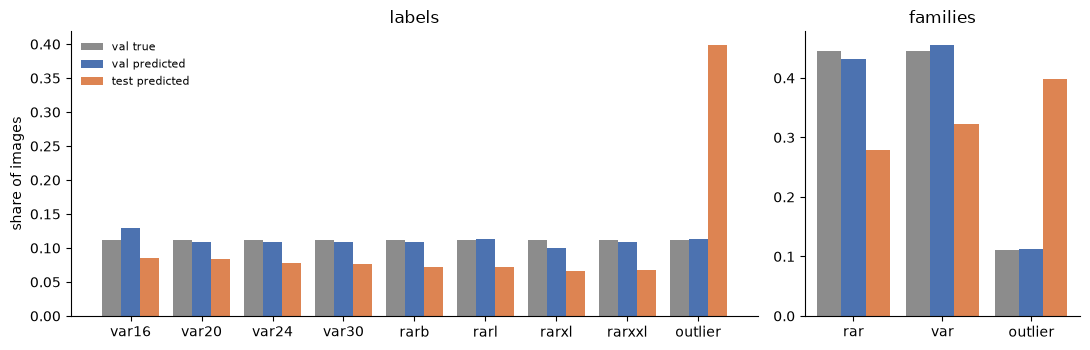

wrote /workspace/iar-model-tracer/results/label_shares.png


In [13]:
pred_fam_val, pred_fam_test = rule2.predict_family(val2).values, rule2.predict_family(test2).values
SETS = {"val true": val2.label.values, "val predicted": pred_val.values, "test predicted": pred_test.values}
shares = pd.DataFrame({k: pd.Series(v).value_counts(normalize=True) for k, v in SETS.items()}).reindex(LABELS).fillna(0)
fam_shares = (pd.DataFrame({k: pd.Series(fam_of(v)).value_counts(normalize=True) for k, v in SETS.items()})
              .reindex(["rar", "var", "outlier"]).fillna(0))
# Size shares within each predicted family (val true: 25% each).
within = {k: pd.Series(v[fam_of(v) != "outlier"]).pipe(lambda s: s.groupby(s.str[:3]).value_counts(normalize=True))
          .droplevel(0) for k, v in SETS.items()}
shares_tab = shares.join(pd.DataFrame(within).add_suffix(" (within family)"))
display(shares_tab.style.format("{:.3f}", na_rep="").set_caption("label shares"))
display(fam_shares.style.format("{:.3f}").set_caption("family shares"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [3, 1.2]})
colours = {"val true": "#8c8c8c", "val predicted": "#4c72b0", "test predicted": "#dd8452"}
for ax, tab in zip(axes, [shares, fam_shares]):
    x, w = np.arange(len(tab)), 0.27
    for i, (k, c) in enumerate(colours.items()):
        ax.bar(x + (i - 1) * w, tab[k], w, color=c, label=k)
    ax.set_xticks(x, tab.index)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("share of images")
axes[0].set_title("labels")
axes[1].set_title("families")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "label_shares.png", dpi=150)
plt.show()
print("wrote", RESULTS / "label_shares.png")

### 4.2 Family / outlier step: Stage 2 z-scores

For each image, $z_f = (\log s_f - \mu_f)/\sigma_f$ (Section 0). The *winning* z is that of the nearest family, $\min_f z_f$. The image is an outlier if the winning z exceeds that family's $\tau_f$. The histograms are split by nearest family, so the predicted outliers are the mass to the right of $\tau$.

**Shift or mixture?** Suppose the test set is a mixture: a share $1 - \pi$ of in-family images distributed like val's, and a share $\pi$ of outliers distributed like val's outliers. Then at any cut-off $z_0$:
$$P_{\text{test}}(z \le z_0) = (1 - \pi)\, P_{\text{val in}}(z \le z_0) + \pi\, P_{\text{val out}}(z \le z_0).$$
Solving gives $1 - \pi = \dfrac{P_{\text{test}} - P_{\text{val out}}}{P_{\text{val in}} - P_{\text{val out}}}$. In the lower tail ($z_0 \le 0.5$), val's outliers contribute almost nothing (2–4%).
- Under such a mixture, the estimate is about the same at every cut-off.
- If instead the whole test distribution were shifted to higher z, the estimate would drift steadily with $z_0$.

This is a diagnostic, not a fit: nothing is chosen from it.

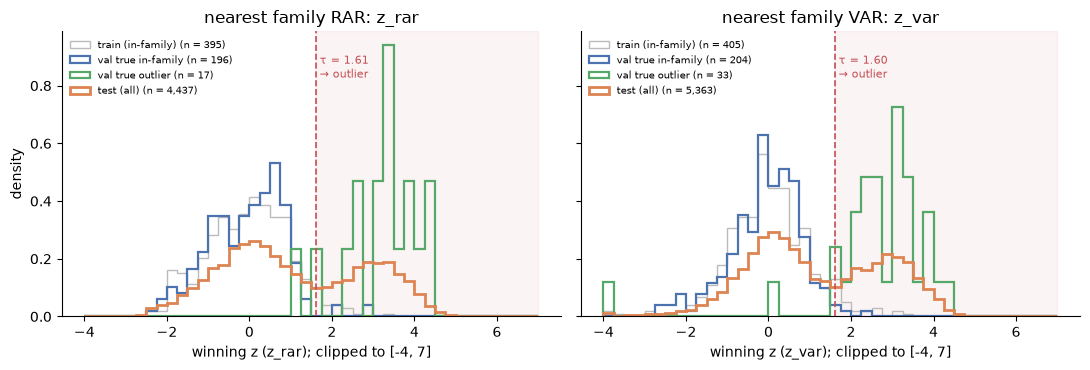

wrote /workspace/iar-model-tracer/results/zscores_val_test.png


,P_test(z <= z0),P_val in(z <= z0),P_val out(z <= z0),implied in-family share 1 - pi,implied outlier share pi
z0,,,,,
-1.000000,0.086,0.145,0.020,0.526,0.474
-0.500000,0.166,0.302,0.020,0.515,0.485
0.000000,0.289,0.492,0.020,0.570,0.430
0.500000,0.424,0.715,0.040,0.569,0.431


In [14]:
def winning_z(d):
    z = rule2.family_z(d)
    return z.min(axis=1).values, np.where(z.z_rar <= z.z_var, "rar", "var")


W = {name: winning_z(d) for name, d in [("train", train2), ("val", val2), ("test", test2)]}
in_val = val2.family.values != "outlier"
groups = {  # name -> (winning z, nearest family)
    "train (in-family)": W["train"],
    "val true in-family": (W["val"][0][in_val], W["val"][1][in_val]),
    "val true outlier": (W["val"][0][~in_val], W["val"][1][~in_val]),
    "test (all)": W["test"],
}
STYLE = {"train (in-family)": dict(color="#bbbbbb", lw=1.0), "val true in-family": dict(color="#4c72b0", lw=1.6),
         "val true outlier": dict(color="#55a868", lw=1.6), "test (all)": dict(color="#dd8452", lw=2.0)}
bins = np.arange(-4, 7.01, 0.25)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, fam in zip(axes, KNOWN_FAMILIES):
    for name, (w, near) in groups.items():
        v = np.clip(w[near == fam], bins[0], bins[-1])
        ax.hist(v, bins=bins, density=True, histtype="step", label=f"{name} (n = {len(v):,})", **STYLE[name])
    ax.axvline(rule2.tau_[fam], color="#c44e52", ls="--", lw=1.2)
    ax.axvspan(rule2.tau_[fam], bins[-1], color="#c44e52", alpha=0.06)
    ax.text(rule2.tau_[fam] + 0.1, ax.get_ylim()[1] * 0.92, f"τ = {rule2.tau_[fam]:.2f}\n→ outlier", color="#c44e52",
            fontsize=8, va="top")
    ax.set_title(f"nearest family {fam.upper()}: z_{fam}")
    ax.set_xlabel(f"winning z (z_{fam}); clipped to [{bins[0]:.0f}, {bins[-1]:.0f}]")
    ax.legend(fontsize=7, frameon=False, loc="upper left")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("density")
fig.tight_layout()
fig.savefig(RESULTS / "zscores_val_test.png", dpi=150)
plt.show()
print("wrote", RESULTS / "zscores_val_test.png")

QS = [5, 25, 50, 75, 95]
rows = []
for fam in KNOWN_FAMILIES:
    tau = rule2.tau_[fam]
    sets = {**{k: (w[near == fam]) for k, (w, near) in groups.items()},
            "val predicted in-family": W["val"][0][(W["val"][1] == fam) & (pred_fam_val == fam)],
            "test predicted in-family": W["test"][0][(W["test"][1] == fam) & (pred_fam_test == fam)],
            "val predicted outlier": W["val"][0][(W["val"][1] == fam) & (pred_fam_val == "outlier")],
            "test predicted outlier": W["test"][0][(W["test"][1] == fam) & (pred_fam_test == "outlier")]}
    for name, w in sets.items():
        rows.append({"nearest family": fam, "set": name, "n": len(w),
                     **{f"q{q}": v for q, v in zip(QS, np.percentile(w, QS))}, "share > tau": np.mean(w > tau)})
zq = pd.DataFrame(rows).set_index(["nearest family", "set"])
display(zq.style.format("{:.2f}", subset=[f"q{q}" for q in QS]).format("{:.3f}", subset=["share > tau"])
        .set_caption("winning z quantiles"))

rows = []
for z0 in [-1.0, -0.5, 0.0, 0.5]:
    p_t, p_in, p_out = (np.mean(w <= z0) for w in (W["test"][0], W["val"][0][in_val], W["val"][0][~in_val]))
    rows.append({"z0": z0, "P_test(z <= z0)": p_t, "P_val in(z <= z0)": p_in, "P_val out(z <= z0)": p_out,
                 "implied in-family share 1 - pi": (p_t - p_out) / (p_in - p_out)})
mixture = pd.DataFrame(rows).set_index("z0")
mixture["implied outlier share pi"] = 1 - mixture["implied in-family share 1 - pi"]
display(mixture.style.format("{:.3f}").set_caption("lower-tail mixture check (both families pooled)"))

### 4.3 Size step: confidence and own-model fit

For images whose predicted family is RAR or VAR, the table and figure compare two quantities on val, test, and the generated holdout (a reference where the model is known):
- **LR max probability**: the Stage 4 logistic regression's probability for its predicted size.
- **$z_{\text{own}}$**: the own-model fit of the predicted size $\hat m$, $z_{\text{own}} = (s_{\hat m} - \mu_{\hat m})/\sigma_{\hat m}$. Here $s_{\hat m}$ is the image's class-mixture log-likelihood under $\hat m$, and $\mu_{\hat m}, \sigma_{\hat m}$ are its mean and SD over $\hat m$'s own generated train images (004's own-sample rule, on the B2 mixture table).

Images from the predicted model should have $z_{\text{own}} \approx N(0, 1)$. Images from another generator would usually fit worse: large $|z_{\text{own}}|$.

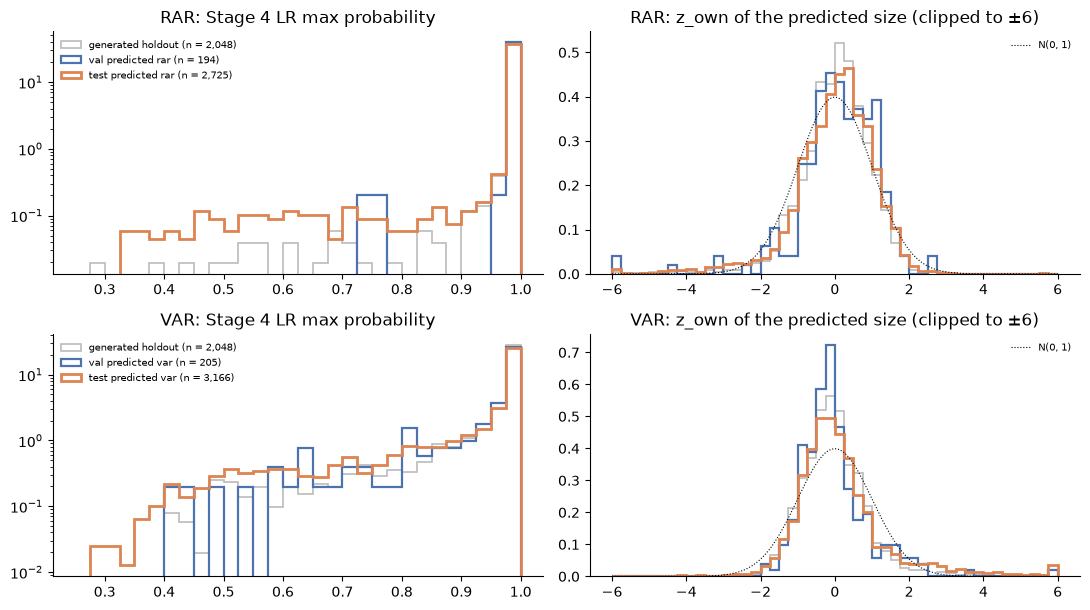

In [15]:
class OwnSampleRule:
    # As in 004: z-score s_m with mean / sd of model m's own generated train samples.
    def __init__(self, sizes, col="sum_logp_guided"):
        self.sizes, self.col = sizes, col

    def fit(self, df):
        own = {m: df.loc[df.label == m, f"{m}:{self.col}"] for m in self.sizes}
        self.mu_ = {m: v.mean() for m, v in own.items()}
        self.sd_ = {m: v.std() for m, v in own.items()}
        return self

    def z(self, df):
        return pd.DataFrame({m: (df[f"{m}:{self.col}"] - self.mu_[m]) / self.sd_[m] for m in self.sizes}, index=df.index)


OWN = {fam: OwnSampleRule(MODELS[fam]).fit(GEN[fam][GEN[fam].split == "train"]) for fam in KNOWN_FAMILIES}


def size_diag(fam, X):
    # LR max probability and z_own of the LR's predicted size, for the rows of the B2 mixture table X.
    P = pd.DataFrame(SIZE_LR[fam].predict_proba(X[lr_features(fam)]), columns=SIZE_LR[fam].classes_)[MODELS[fam]]
    pred = np.array(MODELS[fam])[P.values.argmax(1)]
    z = OWN[fam].z(X).values[np.arange(len(X)), [MODELS[fam].index(p) for p in pred]]
    return pd.DataFrame({"max_prob": P.values.max(1), "z_own": z, "pred": pred})


D = {}
for fam in KNOWN_FAMILIES:
    ho = GEN[fam][GEN[fam].split == "holdout"]
    D[(fam, "generated holdout")] = size_diag(fam, ho)
    for name, d, task, pf in [("val", val2, TASK, pred_fam_val), ("test", test2, TASK_TEST, pred_fam_test)]:
        D[(fam, f"{name} predicted {fam}")] = size_diag(fam, task[fam].loc[d.key.values[pf == fam]])
    # Reference for leaked outliers: val's true outliers, forced through their nearest family's size step.
    D[(fam, f"val true outlier (forced {fam})")] = size_diag(fam, TASK[fam].loc[val2.key.values[~in_val & (W["val"][1] == fam)]])
# Consistency: the sizes here are the final predictions.
for name, d, pred, pf in [("val", val2, pred_val, pred_fam_val), ("test", test2, pred_test, pred_fam_test)]:
    for fam in KNOWN_FAMILIES:
        assert (D[(fam, f"{name} predicted {fam}")].pred.values == pred.values[pf == fam]).all()

rows = []
for (fam, name), df in D.items():
    mp, z = df.max_prob.values, df.z_own.values
    rows.append({"family": fam, "set": name, "n": len(df),
                 **{f"max prob q{q}": v for q, v in zip([5, 25, 50], np.percentile(mp, [5, 25, 50]))},
                 "share max prob >= 0.9": np.mean(mp >= 0.9),
                 "z_own mean": z.mean(), "z_own sd": z.std(), "share |z_own| > 3": np.mean(np.abs(z) > 3)})
sizeq = pd.DataFrame(rows).set_index(["family", "set"])
display(sizeq.style.format("{:.3f}", subset=[c for c in sizeq.columns if c != "n"]))

fig, axes = plt.subplots(2, 2, figsize=(11, 6.2))
SET_STYLE = {"generated holdout": dict(color="#bbbbbb", lw=1.2), "val": dict(color="#4c72b0", lw=1.6),
             "test": dict(color="#dd8452", lw=2.0)}
for r, fam in enumerate(KNOWN_FAMILIES):
    for (f, name), df in D.items():
        if f != fam:
            continue
        if name.startswith("val true outlier"):
            continue  # too few images for a histogram; see the table
        st = SET_STYLE[name.split(" predicted")[0]]
        axes[r, 0].hist(df.max_prob, bins=np.linspace(0.25, 1, 31), density=True, histtype="step",
                        label=f"{name} (n = {len(df):,})", **st)
        axes[r, 1].hist(np.clip(df.z_own, -6, 6), bins=np.linspace(-6, 6, 49), density=True, histtype="step", **st)
    xs = np.linspace(-6, 6, 200)
    axes[r, 1].plot(xs, np.exp(-xs ** 2 / 2) / np.sqrt(2 * np.pi), color="k", lw=0.8, ls=":", label="N(0, 1)")
    axes[r, 0].set_yscale("log")
    axes[r, 0].set_title(f"{fam.upper()}: Stage 4 LR max probability")
    axes[r, 1].set_title(f"{fam.upper()}: z_own of the predicted size (clipped to ±6)")
    axes[r, 0].legend(fontsize=7, frameon=False, loc="upper left")
    axes[r, 1].legend(fontsize=7, frameon=False)
    for ax in axes[r]:
        ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### 4.4 Test images predicted outlier vs val's true outliers

24 random test images predicted "outlier" and 24 random val outliers (seed 0), for visual inspection only.

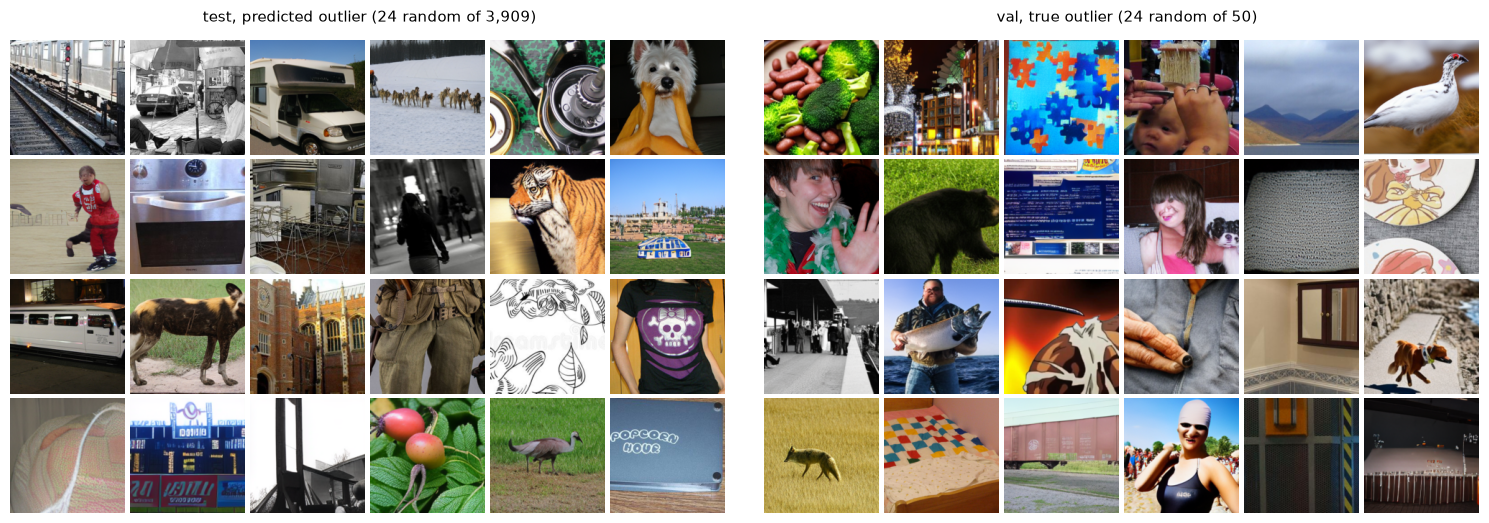

wrote /workspace/iar-model-tracer/results/outliers_test_val.png


In [16]:
rng = np.random.default_rng(SEED)
path_of = idx.set_index("key").path
test_out = rng.choice(test2.key.values[pred_test.values == "outlier"], 24, replace=False)
val_out = rng.choice(val2.key.values[~in_val], 24, replace=False)
fig, axes = plt.subplots(4, 13, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1] * 6 + [0.25] + [1] * 6})
for ax in axes.flat:
    ax.axis("off")
for c0, keys in [(0, test_out), (7, val_out)]:
    for i, k in enumerate(keys):
        axes[i // 6, c0 + i % 6].imshow(Image.open(path_of[k]).convert("RGB").resize((160, 160), Image.BILINEAR))
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.92, wspace=0.04, hspace=0.04)
fig.text(0.25, 0.955, f"test, predicted outlier (24 random of {(pred_test == 'outlier').sum():,})", ha="center", fontsize=11)
fig.text(0.755, 0.955, f"val, true outlier (24 random of {(~in_val).sum()})", ha="center", fontsize=11)
fig.savefig(RESULTS / "outliers_test_val.png", dpi=100)
plt.show()
print("wrote", RESULTS / "outliers_test_val.png")

### 4.5 Expected test accuracy under different outlier shares

**Assumption: val's per-group rates carry over to test.** Only the outlier share $\pi$ changes. From val (final model):
- $a_{\text{in}}$: accuracy on in-family images (the 400 RAR / VAR images);
- $r$: outlier recall (the 50 outliers);
- $f$: the rate at which in-family images are wrongly called outlier.

Then
$$E[\text{accuracy}] = (1 - \pi)\, a_{\text{in}} + \pi\, r, \qquad E[\text{predicted outlier share}] = (1 - \pi)\, f + \pi\, r.$$
The second line can be checked against the observed test value (39.9%). Scenarios whose expected predicted-outlier share is far from it are inconsistent with the assumption.

Two outlier shares are implied rather than assumed:
- by inverting the second formula at the observed share, $\hat\pi = (s_{\text{test}} - f)/(r - f)$;
- by the lower-tail mixture check (4.2, $z_0 = 0$).

The 95% intervals come from 2,000 bootstrap resamples of the val images. They cover the uncertainty in val's rates only, not a failure of the assumption.

The last column is a second variant for the case where the assumption fails for in-family images. It keeps val's outlier recall $r$, but sets the in-family → outlier rate to $f' = (s_{\text{test}} - \pi r)/(1 - \pi)$, the rate that reproduces the observed 39.9%. Accuracy on in-family images that are not called outlier keeps val's rate.

In [17]:
y, p = val2.label.values, pred_val.values
tf, pf = fam_of(y), fam_of(p)
s_test = np.mean(pred_test.values == "outlier")


def rates(b):
    yi, pi_, tfi, pfi = y[b], p[b], tf[b], pf[b]
    inn, out = tfi != "outlier", tfi == "outlier"
    kept = inn & (pfi != "outlier")
    return {"a_in": np.mean(yi[inn] == pi_[inn]), "r": np.mean(pfi[out] == "outlier"),
            "f": np.mean(pfi[inn] == "outlier"), "a_kept": np.mean(yi[kept] == pi_[kept])}


R0 = rates(np.arange(len(y)))
rng = np.random.default_rng(SEED)
RB = pd.DataFrame([rates(rng.integers(0, len(y), len(y))) for _ in range(N_BOOT)])
print("val rates:", {k: round(v, 4) for k, v in R0.items()}, f"| observed test predicted-outlier share {s_test:.4f}")

exp_acc = lambda r, pi: (1 - pi) * r["a_in"] + pi * r["r"]
exp_out = lambda r, pi: (1 - pi) * r["f"] + pi * r["r"]
pi_inv = lambda r: (s_test - r["f"]) / (r["r"] - r["f"])


def acc_matched(r, pi):
    f2 = (s_test - pi * r["r"]) / (1 - pi)
    return np.where((f2 >= 0) & (f2 <= 1), (1 - pi) * (1 - f2) * r["a_kept"] + pi * r["r"], np.nan)


scen = [("as val (50 / 450)", 50 / 450), ("20%", 0.20), ("30%", 0.30), ("40%", 0.40), ("60%", 0.60),
        ("implied by the observed predicted-outlier share", pi_inv(R0)),
        ("implied by the lower-tail mixture check (z0 = 0)", mixture.loc[0.0, "implied outlier share pi"])]
rows = []
for name, pi in scen:
    boot_pi = pi_inv(RB) if name.startswith("implied by the observed") else pi
    acc_b = exp_acc(RB, boot_pi)
    rows.append({"scenario": name, "test outlier share": pi, "expected accuracy": exp_acc(R0, pi),
                 "95% CI low": np.percentile(acc_b, 2.5), "95% CI high": np.percentile(acc_b, 97.5),
                 "expected predicted-outlier share": exp_out(R0, pi), "observed predicted-outlier share": s_test,
                 "accuracy if in-family -> outlier rate matches observed": float(acc_matched(R0, pi))})
expected = pd.DataFrame(rows).set_index("scenario")
expected.to_csv(RESULTS / "expected_test_accuracy.csv", float_format="%.4f")
display(expected.style.format("{:.3f}", na_rep="—"))
print("assumes val's per-group rates (a_in, r, f) carry over to test; wrote", RESULTS / "expected_test_accuracy.csv")

val rates: {'a_in': np.float64(0.9475), 'r': np.float64(0.88), 'f': np.float64(0.0175), 'a_kept': np.float64(0.9644)} | observed test predicted-outlier share 0.3989


,test outlier share,expected accuracy,95% CI low,95% CI high,expected predicted-outlier share,observed predicted-outlier share,accuracy if in-family -> outlier rate matches observed
scenario,,,,,,,
as val (50 / 450),0.111,0.940,0.918,0.961,0.113,0.399,0.665
20%,0.200,0.934,0.910,0.958,0.190,0.399,0.733
30%,0.300,0.927,0.897,0.957,0.276,0.399,0.809
40%,0.400,0.921,0.881,0.957,0.363,0.399,0.885
60%,0.600,0.907,0.850,0.958,0.535,0.399,—
implied by the observed predicted-outlier share,0.442,0.918,0.867,0.956,0.399,0.399,0.918
implied by the lower-tail mixture check (z0 = 0),0.430,0.918,0.877,0.957,0.389,0.399,0.909


assumes val's per-group rates (a_in, r, f) carry over to test; wrote /workspace/iar-model-tracer/results/expected_test_accuracy.csv


### Section 4 result

**The 40% predicted-outlier share on test looks like a real difference in composition, not a shift of the whole test set.** No test labels are available, so this cannot be confirmed; but every distributional check points the same way, and nothing was tuned on test.

1. **Shares.**
   - The model calls 39.9% of test images outliers, against 11.3% of val (true share 11.1%). The rest are 27.8% RAR and 32.3% VAR, against 44.4% each on val.
   - Within each predicted family the four sizes stay balanced on test (23.6–26.6% each; val true 25%). Whatever differs between test and val, it is not the size mix.
2. **Family / outlier step: a mixture, not a shift.**
   - *Two modes.* The test winning-z histogram has two clear modes (figure in 4.2): one at z ≈ 0, matching val's in-family images, and one at z ≈ 3, matching val's true outliers.
   - *In-family images.* Test images predicted in-family have nearly val's quantiles. RAR: q5 / q50 / q95 of −1.76 / −0.02 / 1.32 vs val's −1.62 / 0.02 / 1.11. VAR: −1.57 / 0.09 / 1.36 vs −1.62 / −0.02 / 1.15. The slightly higher q95 is what outliers falling just below τ would produce (val's outliers start at z ≈ 1).
   - *Predicted outliers.* Test images predicted outlier sit where val's outliers do (median z 3.01 / 2.90 vs 3.27 / 2.88 for RAR / VAR). In-family images with a shifted tail would pile up just above τ ≈ 1.6 instead.
   - *Lower-tail check.* The share of test images in the lower tail, relative to val's in-family images, implies an outlier share of 43–49% at every cut-off ($z_0$ from −1 to 0.5). A shift of the whole distribution would make this estimate drift with $z_0$. The estimate is noisy, because val has only 58 in-family images below z = −1.
3. **Size step: transfers, with a residual for VAR.**
   - *RAR.* Test images predicted RAR are about as confident as val's: median LR max probability 1.000, 95.2% at ≥ 0.9 vs 99.0% on val. The own-model fit is normal: $z_{\text{own}}$ sd 1.12, 2.2% with $|z_{\text{own}}| > 3$ (val 1.27, 2.6%).
   - *VAR.* Test images predicted VAR are somewhat less confident: 77.3% at ≥ 0.9 vs 81.5% on val and 85.7% on the generated holdout.
   - *Leaked outliers explain most of this.* With the implied ~44% outliers and val's miss rate of 12%, about 520 test outliers would be given a family, against 6 on val. Val's true outliers forced through the size step are much less confident: 41% (RAR) and 33% (VAR) at ≥ 0.9. Mixing them in at val's 2 : 4 RAR : VAR split gives expected shares of 95.3% (RAR) and 76.2% (VAR). The observed values are 95.2% and 77.3%. This is rough: the split rests on 6 val images, and the outlier references on 17 and 33.
   - *What remains unexplained.* VAR's $z_{\text{own}}$ is wider on test than this predicts: sd 1.44 vs 1.03 on val, and 4.2% (about 130 images) with $|z_{\text{own}}| > 3$ against roughly 2% expected. Some test images predicted VAR fit their predicted depth worse than any val image does. Without labels, we cannot tell whether they are outliers unlike val's, or VAR images processed differently.
4. **Visual check.** The test images predicted outlier and val's true outliers look alike (ImageNet-style scenes, a few greyscale images in both). Nothing visibly marks either group, as expected for images from other generators.
5. **Expected test accuracy.** This *assumes val's per-group rates carry over to test*: 94.75% accuracy on in-family images, 88% outlier recall, 1.75% of in-family images called outlier.
   - *Range.* Expected accuracy then falls only slowly with the outlier share: 94.0% at 11%, 92.1% at 40%, 90.7% at 60%. Outlier recall (88%) is lower than in-family accuracy (94.75%), so more outliers means slightly lower accuracy.
   - *Consistent shares.* Under these rates, the observed 39.9% predicted-outlier share implies an outlier share of 44.2%, and the lower-tail check gives 43%. Both give an expected accuracy of about 91.8%, with a val-only bootstrap interval of [86.7, 95.6].
   - *Inconsistent scenarios.* An 11% (val-like) outlier share would predict 11.3% outliers, not 39.9%, so it contradicts the assumption. If test really had 11% outliers, about 34% of its in-family images would have to be called outlier, and accuracy would drop to about 66.5% (last column). The z-score evidence above argues against this case but cannot exclude it.

**What this does not show.**
- *That the predicted outliers are outliers.* The z-scores only show that they are atypical of both families, in the way val's outliers are.
- *That test's outliers resemble val's.* If they come from different generators, outlier recall on test could differ from 88% in either direction.
- *The VAR residual (item 3).* It is the one place where test does not look like val.

**An observation, not acted on.** Val's true outliers fit the RAR models very badly ($z_{\text{own}}$ mean −6.6). The generator likelihood might therefore also help detect outliers. Any such use would have to be specified in advance and evaluated on val. It must not be chosen from the test distributions shown here.

## 5. Final results

A compact summary of Sections 1–4. It is printed below and saved as `results/final_summary.json` and `results/final_summary.md`. Paths are relative to the repo root.

In [18]:
def r6(v):
    return None if v is None or (isinstance(v, float) and np.isnan(v)) else round(float(v), 6)


def md_table(df, fmt="{:.3f}", index_name=None):
    # Markdown table without extra dependencies; floats formatted with fmt, other values as text.
    cell = lambda v: fmt.format(v) if isinstance(v, (float, np.floating)) else str(v)
    head = [index_name or df.index.name or ""] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join([str(i)] + [cell(v) for v in row]) + " |" for i, row in zip(df.index, df.values)]
    return "\n".join(lines)


rel = lambda p: Path(p).relative_to(REPO).as_posix()
SUMMARY_JSON, SUMMARY_MD = RESULTS / "final_summary.json", RESULTS / "final_summary.md"
LATER = {"feature_ablation.csv"}  # written by Section 6, after this summary
result_files = sorted({p.name for p in RESULTS.iterdir() if p.is_file()} | {SUMMARY_JSON.name, SUMMARY_MD.name} | LATER)
KEY = ["accuracy", "family_accuracy", "outlier_recall", "outlier_precision", "size_accuracy_given_family"]
n_err = int(breakdown.loc["total", "errors"])

summary = {
    "stages_val": {str(st): {"method": stages.loc[st, "method"], **{k: r6(stages.loc[st, k]) for k in KEY}}
                   for st in STAGES},
    "final_model": {
        "method": "Stage 2 family / outlier (NearestFamilyThreshold on fine-tuned D^-1 signals, q = 0.95) + Stage 4 size "
                  "(logistic regression on generator-likelihood summaries; recovered tokens, top-5 classes, B2 mixture)",
        "val": {**{k: r6(final_val[k]) for k in KEY + ["family_recall_rar", "family_recall_var"]}, "n": len(val2),
                "accuracy_95ci": [r6(ci.loc["accuracy", "95% CI low"]), r6(ci.loc["accuracy", "95% CI high"])],
                "size_accuracy_given_family_95ci": [r6(ci.loc["size accuracy given family", "95% CI low"]),
                                                    r6(ci.loc["size accuracy given family", "95% CI high"])],
                "bootstrap": f"{N_BOOT} resamples of the val images, seed {SEED}"},
        "val_error_breakdown": {**{t: int(breakdown.loc[t, "errors"]) for t in TYPES}, "total": n_err},
        "test_predicted_shares": {"n": len(test2), "labels": {l: r6(shares.loc[l, "test predicted"]) for l in LABELS},
                                  "families": {f: r6(fam_shares.loc[f, "test predicted"]) for f in fam_shares.index}},
        "expected_test_accuracy_if_val_rates_hold": {
            name: {"test_outlier_share": r6(row["test outlier share"]), "expected_accuracy": r6(row["expected accuracy"]),
                   "95ci": [r6(row["95% CI low"]), r6(row["95% CI high"])],
                   "expected_predicted_outlier_share": r6(row["expected predicted-outlier share"])}
            for name, row in expected.iterrows()},
        "observed_test_predicted_outlier_share": r6(s_test),
    },
    "submission_checks": {chk: {col: table.loc[chk, col] for col in table.columns} for chk in table.index},
    "files": {"submission": rel(SUBMISSION), "submission_val": rel(SUBMISSION_VAL),
              "results": [f"results/{n}" for n in result_files],
              "outside the repo": [str(FINAL / "pred_val.csv")] + [str(CACHE / f"stage{s}" / "metrics.json") for s in STAGES]},
}

fv = summary["final_model"]["val"]
stage_tab = stages[KEY].rename(columns=lambda c: c.replace("_", " "))
stage_tab.index = [f"Stage {s}" for s in stage_tab.index]
err_tab = breakdown[["errors", "share of errors", "decided by"]].copy()
err_tab["share of errors"] = err_tab["share of errors"].map("{:.1%}".format)
share_tab = pd.DataFrame({"test predicted": shares["test predicted"], "val predicted": shares["val predicted"],
                          "val true": shares["val true"]})
fam_tab = fam_shares[["test predicted", "val predicted", "val true"]]
text = "\n\n".join([
    "# Final results",
    "## Val metrics per stage (450 images)\n\n" + md_table(stage_tab, index_name="stage"),
    "## Final model (Stage 2 family / outlier + Stage 4 size)\n\n"
    f"- val accuracy **{fv['accuracy']:.3f}**, 95% CI [{fv['accuracy_95ci'][0]:.3f}, {fv['accuracy_95ci'][1]:.3f}]\n"
    f"- size accuracy given family **{fv['size_accuracy_given_family']:.3f}**, 95% CI "
    f"[{fv['size_accuracy_given_family_95ci'][0]:.3f}, {fv['size_accuracy_given_family_95ci'][1]:.3f}]\n"
    f"- family accuracy {fv['family_accuracy']:.3f}, outlier recall / precision {fv['outlier_recall']:.3f} / "
    f"{fv['outlier_precision']:.3f}\n"
    f"- bootstrap: {fv['bootstrap']}",
    f"### Val errors ({n_err} of {len(val2)})\n\n" + md_table(err_tab, fmt="{}", index_name="error type"),
    f"### Predicted shares on test ({len(test2):,} images), next to val\n\n" + md_table(share_tab, index_name="label")
    + "\n\n" + md_table(fam_tab, index_name="family"),
    "### Expected test accuracy, if val's per-group rates carry over to test (Section 4.5)\n\n"
    + md_table(expected[["test outlier share", "expected accuracy", "95% CI low", "95% CI high",
                         "expected predicted-outlier share"]], index_name="scenario")
    + f"\n\nObserved predicted-outlier share on test: {s_test:.3f}. Scenarios whose expected predicted-outlier share "
      "is far from it are inconsistent with the assumption (e.g. an 11% outlier share would need about a third of the "
      "in-family test images to be called outlier; Section 4.5, last column).",
    "## Submission checks (Section 3)\n\n" + md_table(table, fmt="{}", index_name="check"),
    "## Files\n\n" + "\n".join([f"- `{summary['files']['submission']}`: test predictions (the submission)",
                                f"- `{summary['files']['submission_val']}`: val predictions, same format"]
                               + [f"- `{f}`" + (" (Section 6)" if Path(f).name in LATER else "")
                                  for f in summary["files"]["results"]]
                               + [f"- `{f}` (cache, not in the repo)" for f in summary["files"]["outside the repo"]]),
])
SUMMARY_JSON.write_text(json.dumps(summary, indent=2) + "\n")
SUMMARY_MD.write_text(text + "\n")
assert json.loads(SUMMARY_JSON.read_text()) == summary
assert all((REPO / f).exists() for f in summary["files"]["results"] + [summary["files"]["submission"],
                                                                         summary["files"]["submission_val"]]
           if Path(f).name not in LATER)
print(text)
print(f"\nwrote {SUMMARY_JSON} and {SUMMARY_MD}")

# Final results

## Val metrics per stage (450 images)

| stage | accuracy | family accuracy | outlier recall | outlier precision | size accuracy given family |
|---|---|---|---|---|---|
| Stage 1 | 0.236 | 0.838 | 0.320 | 0.533 | 0.249 |
| Stage 2 | 0.316 | 0.960 | 0.880 | 0.863 | 0.253 |
| Stage 3 | 0.316 | 0.960 | 0.880 | 0.863 | 0.253 |
| Stage 4 | 0.940 | 0.960 | 0.880 | 0.863 | 0.977 |

## Final model (Stage 2 family / outlier + Stage 4 size)

- val accuracy **0.940**, 95% CI [0.918, 0.960]
- size accuracy given family **0.977**, 95% CI [0.961, 0.990]
- family accuracy 0.960, outlier recall / precision 0.880 / 0.863
- bootstrap: 2000 resamples of the val images, seed 0

### Val errors (27 of 450)

| error type | errors | share of errors | decided by |
|---|---|---|---|
| family error (RAR <-> VAR) | 5 | 18.5% | Stage 2 (family / outlier) |
| outlier false positive | 7 | 25.9% | Stage 2 (family / outlier) |
| outlier miss | 6 | 22.2% | Stage 2 (family / outlier) |
| size error (co

## 6. What carries the VAR size signal

A feature-group ablation of the Stage 4 size classifier. It is a diagnostic only: **the final model is not changed**, and the refits below use their own variables.

The final LR uses, for each of the family's 4 models, these per-image summaries of the B2 mixture (top-5 classes):

| group | per-model feature | meaning |
|---|---|---|
| `logp_cond` | `mean_logp_cond` | mean log-softmax of the class-conditional logits at the true token |
| `logp_uncond` | `mean_logp_uncond` | the same for the unconditional (null-class) logits; does not depend on the class |
| `logp_guided` | `mean_logp_guided` | mean log-probability under the guided sampling distribution (the mixture over classes) |
| `rank_guided` | `mean_rank_guided` | mean number of codes with a higher guided logit than the true token |
| `min20_logp_guided` | `min20_logp_guided` | mean of the lowest 20% of the guided log-probabilities |
| `in_support_rate` | `in_support_rate` | VAR only: share of tokens inside the sampler's top-k = 900 / top-p = 0.96 support |

Each group therefore has 4 features, one per model. RAR has 20 features in 5 groups, and VAR 24 in 6.

**Variants.** For each family:
- *all*: the final model's features;
- *without g*: every group but $g$;
- *only g*: group $g$ alone.

Every variant is fit exactly as in 004 (standardisation, then a multinomial logistic regression with `max_iter = 5000`) on the generated train split. Two accuracies are reported:
- on the generated holdout (512 per size);
- on the task's train + val images of that family (150 per size), with the true family given, as in 004's transfer criterion.

Intervals are 95% bootstrap intervals (2,000 resamples, seed 0). The *all* row must reproduce 004's numbers.

The groups are strongly correlated with each other: `logp_guided` is a mixture of `logp_cond` and `logp_uncond`. So *without g* measures what $g$ adds beyond the other groups, not how much size information $g$ carries. That is what *only g* measures.

In [19]:
GROUPS = {"logp_cond": "mean_logp_cond", "logp_uncond": "mean_logp_uncond", "logp_guided": "mean_logp_guided",
          "rank_guided": "mean_rank_guided", "min20_logp_guided": "min20_logp_guided",
          "in_support_rate": "in_support_rate"}


def group_features(fam, groups):
    return [f"{m}:{GROUPS[g]}" for m in MODELS[fam] for g in groups]


def acc_ci(correct, rng):
    b = [correct[rng.integers(0, len(correct), len(correct))].mean() for _ in range(N_BOOT)]
    return correct.mean(), *np.percentile(b, [2.5, 97.5])


task_in = df2[df2.split.isin(["train", "val"])]
rows = []
for fam in KNOWN_FAMILIES:
    groups = [g for g in GROUPS if fam == "var" or g != "in_support_rate"]
    assert group_features(fam, groups) == sorted(lr_features(fam), key=group_features(fam, groups).index)
    assert set(group_features(fam, groups)) == set(lr_features(fam))
    tr, ho = GEN[fam][GEN[fam].split == "train"], GEN[fam][GEN[fam].split == "holdout"]
    tt = task_in[task_in.family == fam]
    X_task, y_task = TASK[fam].loc[tt.key.values], tt.label.values
    assert (pd.Series(y_task).value_counts() == 150).all() and (ho.label.value_counts() == 512).all()
    variants = [("all", None, groups)] + [(f"without {g}", g, [h for h in groups if h != g]) for g in groups] \
             + [(f"only {g}", g, [g]) for g in groups]
    for name, g, use in variants:
        feats = lr_features(fam) if name == "all" else group_features(fam, use)
        lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(tr[feats], tr.label)
        predict = lambda X: np.array(MODELS[fam])[
            pd.DataFrame(lr.predict_log_proba(X[feats]), columns=lr.classes_)[MODELS[fam]].values.argmax(1)]
        p_ho, p_task = predict(ho), predict(X_task)
        if name == "all":  # identical to the final model's size classifier
            assert (p_ho == SIZE_LR[fam].predict(ho[lr_features(fam)])).all()
        rng = np.random.default_rng(SEED)
        h, h_lo, h_hi = acc_ci(p_ho == ho.label.values, rng)
        t, t_lo, t_hi = acc_ci(p_task == y_task, rng)
        rows.append({"family": fam, "variant": name, "group": g or "", "n features": len(feats),
                     "holdout acc": h, "holdout lo": h_lo, "holdout hi": h_hi,
                     "task train+val acc": t, "task lo": t_lo, "task hi": t_hi})
abl = pd.DataFrame(rows)
for fam in KNOWN_FAMILIES:
    base = abl[(abl.family == fam) & (abl.variant == "all")].iloc[0]
    m = abl.family == fam
    abl.loc[m, "holdout change"] = abl.loc[m, "holdout acc"] - base["holdout acc"]
    abl.loc[m, "task change"] = abl.loc[m, "task train+val acc"] - base["task train+val acc"]
# The "all" rows reproduce 004 (Sections 3-4, logistic regression on B2 (ii) mix; printed to 3 decimals).
REF_004 = {"rar": (0.995, 0.987), "var": (0.965, 0.955)}
for fam, (h, t) in REF_004.items():
    base = abl[(abl.family == fam) & (abl.variant == "all")].iloc[0]
    assert abs(base["holdout acc"] - h) <= 5e-4 and abs(base["task train+val acc"] - t) <= 5e-4, (fam, base)
abl.to_csv(RESULTS / "feature_ablation.csv", index=False, float_format="%.4f")
assert "results/feature_ablation.csv" in json.loads(SUMMARY_JSON.read_text())["files"]["results"]  # listed in Section 5

show = abl.set_index(["family", "variant"])
show["holdout"] = [f"{a:.3f} [{lo:.3f}, {hi:.3f}]" for a, lo, hi in show[["holdout acc", "holdout lo", "holdout hi"]].values]
show["task train+val"] = [f"{a:.3f} [{lo:.3f}, {hi:.3f}]" for a, lo, hi in
                          show[["task train+val acc", "task lo", "task hi"]].values]
show = show[["n features", "holdout", "holdout change", "task train+val", "task change"]]
for fam in KNOWN_FAMILIES:
    display(show.loc[fam].style.format("{:+.3f}", subset=["holdout change", "task change"])
            .background_gradient(cmap="RdBu", vmin=-0.3, vmax=0.3, subset=["holdout change", "task change"])
            .set_caption(f"{fam.upper()}: size accuracy (4-way, chance 0.25) by feature group"))
print("wrote", RESULTS / "feature_ablation.csv")

,n features,holdout,holdout change,task train+val,task change
variant,,,,,
all,20,"0.995 [0.991, 0.998]",+0.000,"0.987 [0.977, 0.995]",+0.000
without logp_cond,16,"0.995 [0.991, 0.998]",+0.000,"0.987 [0.977, 0.995]",+0.000
without logp_uncond,16,"0.995 [0.991, 0.998]",+0.000,"0.987 [0.977, 0.995]",+0.000
without logp_guided,16,"0.995 [0.991, 0.998]",+0.000,"0.987 [0.977, 0.995]",+0.000
without rank_guided,16,"0.996 [0.993, 0.998]",+0.001,"0.987 [0.977, 0.995]",+0.000
without min20_logp_guided,16,"0.995 [0.992, 0.998]",+0.000,"0.987 [0.977, 0.995]",+0.000
only logp_cond,4,"0.996 [0.993, 0.999]",+0.001,"0.992 [0.983, 0.998]",+0.005
only logp_uncond,4,"0.459 [0.438, 0.481]",-0.536,"0.435 [0.395, 0.475]",-0.552
only logp_guided,4,"0.993 [0.989, 0.996]",-0.002,"0.988 [0.978, 0.997]",+0.002


,n features,holdout,holdout change,task train+val,task change
variant,,,,,
all,24,"0.965 [0.956, 0.973]",+0.000,"0.955 [0.938, 0.972]",+0.000
without logp_cond,20,"0.962 [0.953, 0.970]",-0.003,"0.958 [0.942, 0.973]",+0.003
without logp_uncond,20,"0.964 [0.956, 0.972]",-0.000,"0.957 [0.940, 0.973]",+0.002
without logp_guided,20,"0.961 [0.953, 0.970]",-0.003,"0.950 [0.930, 0.967]",-0.005
without rank_guided,20,"0.960 [0.951, 0.969]",-0.005,"0.953 [0.935, 0.970]",-0.002
without min20_logp_guided,20,"0.958 [0.950, 0.967]",-0.006,"0.948 [0.930, 0.965]",-0.007
without in_support_rate,20,"0.964 [0.955, 0.972]",-0.001,"0.958 [0.942, 0.973]",+0.003
only logp_cond,4,"0.950 [0.940, 0.958]",-0.015,"0.927 [0.905, 0.947]",-0.028
only logp_uncond,4,"0.607 [0.585, 0.629]",-0.357,"0.625 [0.587, 0.665]",-0.330


wrote /workspace/iar-model-tracer/results/feature_ablation.csv


### Section 6 result

**No single feature group is necessary, and one group of 4 features is nearly enough.** Removing any one group changes accuracy by at most 0.7 points, for either family, on either data set. So the groups largely carry the same information. Generated-holdout and task accuracies move together in every variant (within about 3 points), so the ablation conclusions transfer to the task images.

1. **The class-conditional log-probability carries the size signal.**
   - *RAR.* `logp_cond`, `logp_guided` and `rank_guided` each reach 99% or more on their own, holdout and task alike; `min20_logp_guided` alone reaches 98–99%.
   - *VAR.* `logp_cond` alone reaches 95.0% (holdout) / 92.7% (task), and `rank_guided` alone 94.7% / 92.8%. Both are within 2–3 points of the full model (96.5% / 95.5%).
2. **Comparing the four models is what matters, not any single likelihood.**
   - *The puzzle from 004.* There, VAR's single guided likelihood picked the right depth for only 66% of B2 holdout images (raw argmax of $s_m$), and the own-sample rule reached 53%.
   - *The same 4 features in an LR.* An LR on just those 4 `logp_guided` features reaches 90.9%. The LR's gain therefore comes mainly from weighing the four models' likelihoods against each other: a per-model offset and scale learned on generated data. It does not come from combining many feature types.
   - *This answers 004's open question* ("which features carry VAR after recovery").
3. **For VAR, the unguided conditional is more informative than the guided distribution** (95.0% vs 90.9% alone). The guided distribution is what the sampler draws from, so this is not what the hypothesis predicted. A possible reason: the guidance extrapolation $(1 + \tau_s)\, l_c - \tau_s\, l_u$ sharpens the distribution. That would make the guided log-probabilities more sensitive to the 73% of VAR tokens that recovery gets wrong. This was not tested. For RAR, both reach 99%+.
4. **Even without the class, the models' predictions carry size information.** `logp_uncond` (null class, no class estimate involved) alone gives 46% for RAR and 61% for VAR, well above chance (25%). These are still predictions from each token's context. Stage 3's marginal token statistics stayed at chance even with the true tokens. Most of the signal still needs the class: the conditional features are far stronger.
5. **The weakest-token summary works for RAR but not for VAR.** `min20_logp_guided` alone gives 99.0% for RAR but only 49.5% for VAR.
   - *Possible reason:* a guess, not tested. With only 27% of VAR tokens recovered, the lowest 20% of log-probabilities are probably dominated by wrongly recovered tokens, which every depth finds unlikely.
   - *`in_support_rate`* (VAR only) is informative on its own (76.5%) but adds nothing to the other groups (−0.1 / +0.3 points without it).

**What this does not show.**
- Pairs of groups were not tested.
- The final model was not changed: a smaller feature set (e.g. `logp_cond` + `rank_guided`) might do as well, but it would have to be pre-registered and evaluated, not chosen from this table.
- The differences between the *without g* variants (all within ±0.7 points) are inside the bootstrap intervals.